# Image segmentation with a U-Net-like architecture

**Author:** [fchollet](https://twitter.com/fchollet)<br>
**Date created:** 2019/03/20<br>
**Last modified:** 2020/04/20<br>
**Description:** Image segmentation model trained from scratch on the Oxford Pets dataset.

In [12]:
%pip install -q -U tensorflow-datasets importlib_resources

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

SEED = 42
IMG_SIZE = (128, 128)
TRAIN_COUNT = 800
VAL_COUNT = 200
BATCH_SIZE = 16
EPOCHS = 8
NUM_CLASSES = 3
CLASS_NAMES = ["Животное", "Граница", "Фон"]

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Download the data

In [13]:
raw = tfds.load("oxford_iiit_pet", split="train", shuffle_files=False)
# Один фиксированный случайный порядок: обучающая и валидационная выборки не пересекаются.
raw = raw.shuffle(3680, seed=SEED, reshuffle_each_iteration=False)
train_raw = raw.take(TRAIN_COUNT)
val_raw = raw.skip(TRAIN_COUNT).take(VAL_COUNT)

def preprocess(example):
    image = tf.image.resize(example["image"], IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.image.resize(
        example["segmentation_mask"], IMG_SIZE,
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )
    mask = tf.cast(mask, tf.int32) - 1
    return image, mask

train_ds = (train_raw.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
            .cache().shuffle(TRAIN_COUNT, seed=SEED)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = (val_raw.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
          .cache().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
print(f"Train: {TRAIN_COUNT}, validation: {VAL_COUNT}")


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Train: 800, validation: 200


## What does one input image and corresponding segmentation mask look like?

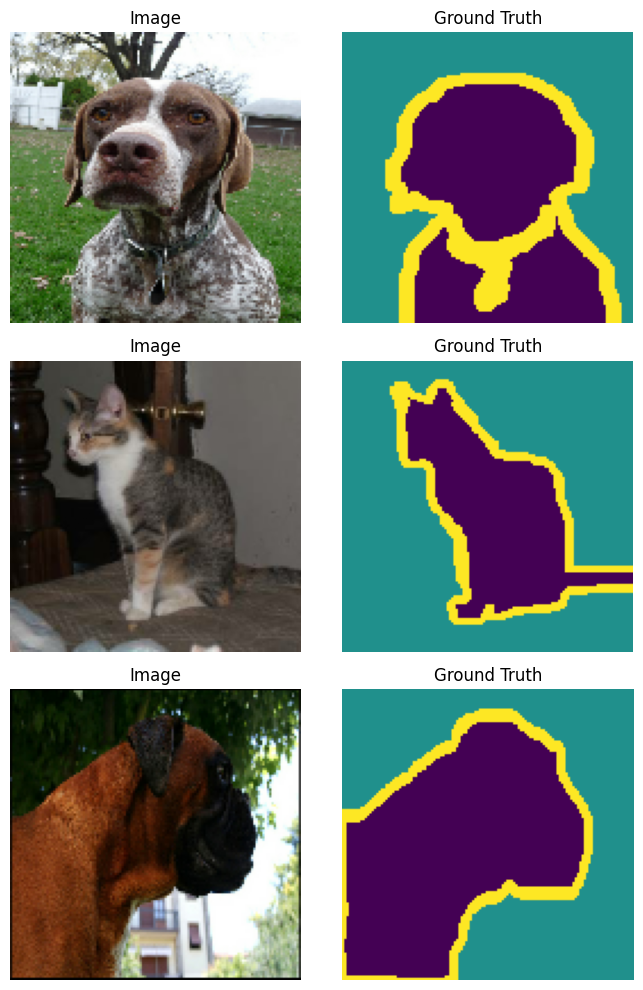

In [14]:
images, masks = next(iter(train_ds))
fig, axes = plt.subplots(3, 2, figsize=(7, 10))
for i in range(3):
    axes[i, 0].imshow(images[i]); axes[i, 0].set_title("Image")
    axes[i, 1].imshow(masks[i, ..., 0], cmap="viridis", vmin=0, vmax=2)
    axes[i, 1].set_title("Ground Truth")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout()
plt.show()

4. Небольшая U-Net
Encoder сжимает изображение, decoder восстанавливает разрешение, skip-connections помогают сохранить детали.

## Prepare model

In [15]:
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return x

def build_unet():
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)
    bottleneck = conv_block(p3, 128)
    u3 = layers.UpSampling2D()(bottleneck)
    u3 = layers.Concatenate()([u3, c3])
    c4 = conv_block(u3, 64)
    u2 = layers.UpSampling2D()(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = conv_block(u2, 32)
    u1 = layers.UpSampling2D()(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = conv_block(u1, 16)
    outputs = layers.Conv2D(NUM_CLASSES, 1, activation="softmax")(c6)
    return Model(inputs, outputs)

model = build_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │      2,320 │ conv2d_9[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │      4,640 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_11[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_13[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 16, 16,    │          0 │ conv2d_14[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_15[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_8     │ (None, 32, 32,    │          0 │ conv2d_16[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d_8[… │
│ (Concatenate)       │ 192)              │            │ conv2d_14[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 32, 32,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_17[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_9     │ (None, 64, 64,    │          0 │ conv2d_18[0][0] 

 Total params: 487,331 (1.86 MB)

 Trainable params: 487,331 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

## Train the model

In [24]:
EPOCHS = 8 # Mean IoU: 0.481
# EPOCHS = 16 # Mean IoU: 0.585
# EPOCHS = 32 # Mean IoU: 0.601

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

Epoch 1/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.8539 - loss: 0.3744 - val_accuracy: 0.8197 - val_loss: 0.4697
Epoch 2/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.8579 - loss: 0.3615 - val_accuracy: 0.8223 - val_loss: 0.4728
Epoch 3/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.8678 - loss: 0.3368 - val_accuracy: 0.8270 - val_loss: 0.4607
Epoch 4/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8737 - loss: 0.3241 - val_accuracy: 0.8343 - val_loss: 0.4540
Epoch 5/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8756 - loss: 0.3178 - val_accuracy: 0.8187 - val_loss: 0.4896
Epoch 6/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8815 - loss: 0.3023 - val_accuracy: 0.8316 - val_loss: 0.4759
Epoch 7/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8826 - loss: 0.2976 - val_accuracy: 0.8229 - val_loss: 0.5159
Epoch 8/32
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8934 - loss: 0.2713 - val_accuracy: 0.8251 - v

## Графики обучения

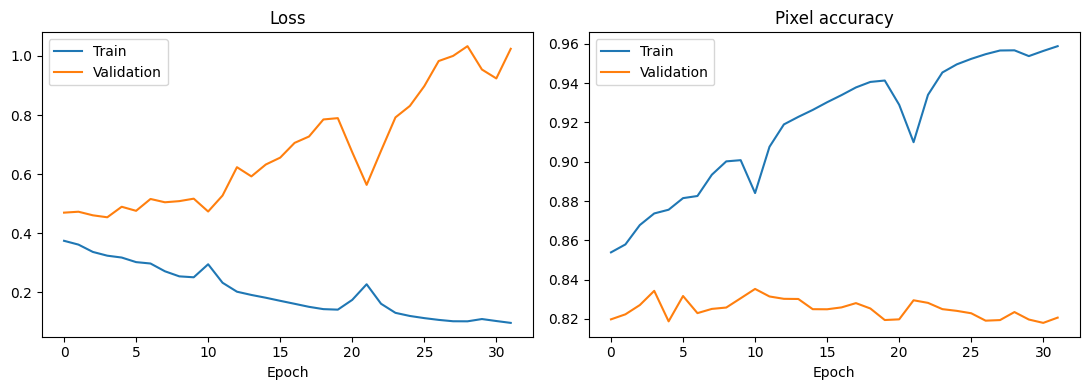

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="Train")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("Pixel accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Расчёт IoU на всей валидационной выборке

Для каждого класса: IoU = TP / (TP + FP + FN). Mean IoU — среднее по трём классам. Метрика считается по всей выборке, а не по одному изображению.

In [26]:
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
for batch_images, batch_masks in val_ds:
    probs = model.predict_on_batch(batch_images)
    preds = np.argmax(probs, axis=-1).astype(np.int32)
    true_masks = tf.squeeze(batch_masks, axis=-1)
    cm = tf.math.confusion_matrix(
        tf.reshape(true_masks, [-1]),
        tf.reshape(preds, [-1]),
        num_classes=NUM_CLASSES
    )
    confusion += cm.numpy()

intersection = np.diag(confusion)
union = confusion.sum(axis=0) + confusion.sum(axis=1) - intersection
ious = np.divide(intersection, union, out=np.zeros(NUM_CLASSES, dtype=float), where=union > 0)
for name, score in zip(CLASS_NAMES, ious):
    print(f"IoU ({name}): {score:.3f}")
print(f"Mean IoU: {ious.mean():.3f}")

IoU (Животное): 0.670
IoU (Граница): 0.812
IoU (Фон): 0.321
Mean IoU: 0.601


## Image / Ground Truth / Prediction

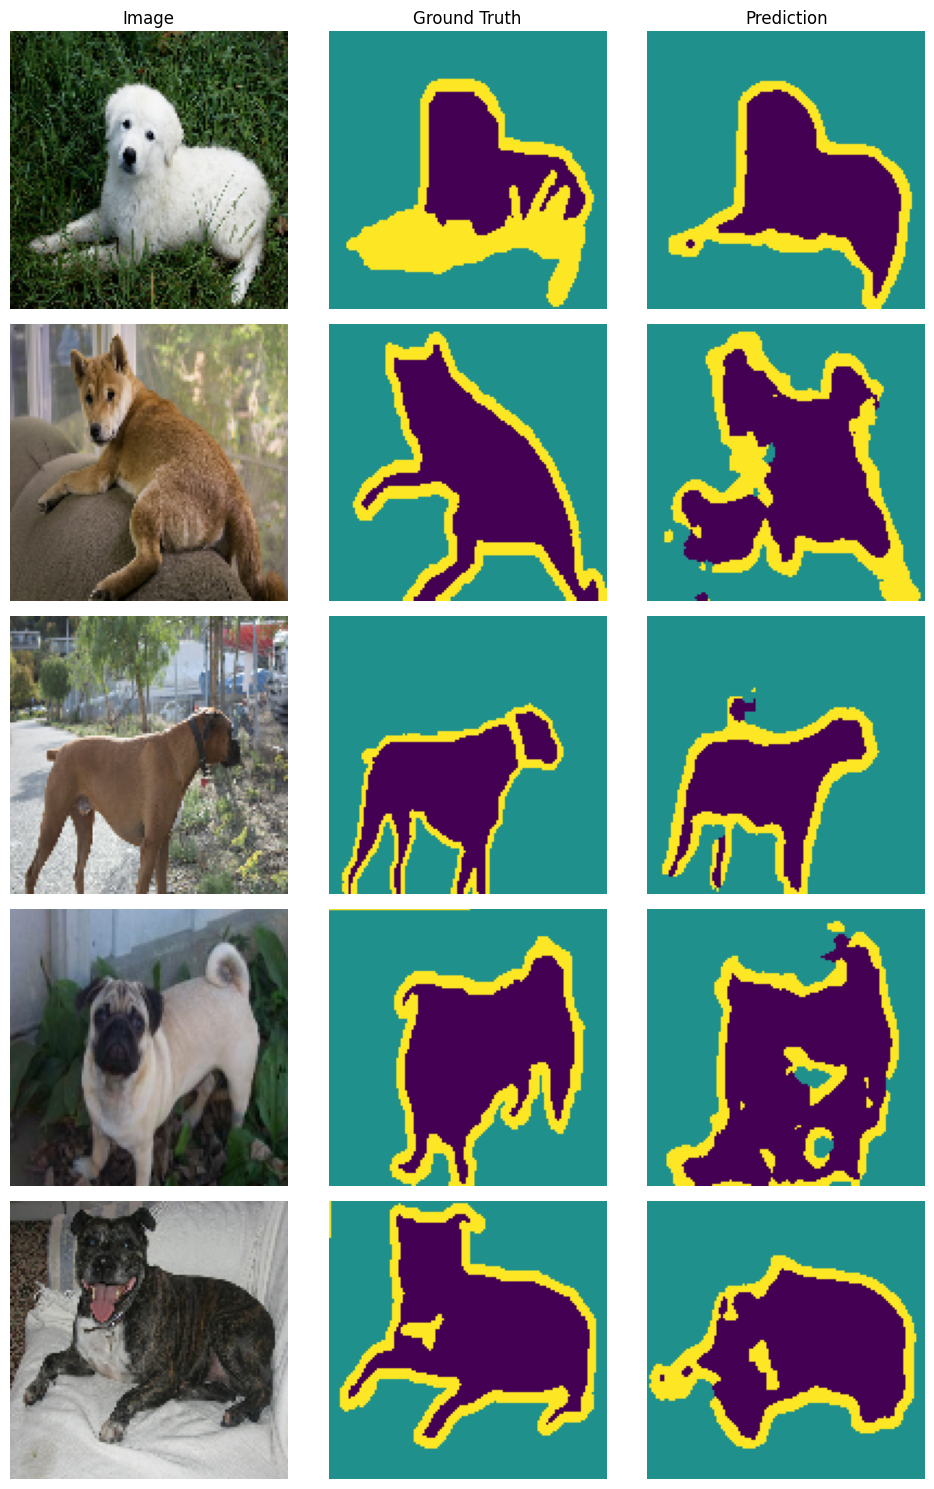

In [27]:
sample_images, sample_masks = next(iter(val_ds))
probabilities = model.predict(sample_images, verbose=0)
predictions = np.argmax(probabilities, axis=-1)

N = 5
fig, axes = plt.subplots(N, 3, figsize=(10, 3 * N))
for i in range(N):
    axes[i, 0].imshow(sample_images[i])
    axes[i, 1].imshow(sample_masks[i, ..., 0], cmap="viridis", vmin=0, vmax=2)
    axes[i, 2].imshow(predictions[i], cmap="viridis", vmin=0, vmax=2)
    for ax in axes[i]: ax.axis("off")
for ax, name in zip(axes[0], ["Image", "Ground Truth", "Prediction"]):
    ax.set_title(name)
plt.tight_layout(); plt.show()